# Parameters
## Main parameters

In [1]:
cell_type    = 'CD8'
learn_rate   = 1e-3
batch_size   = 32

## Additional parameters

In [2]:
data_dir         = "/Users/wsun/research/CAT/data/"
results_dir      = "model/"
max_epochs       = 20
model_patience   = 10
validating_frac  = 0.10
classify_layers  = []
encode_layers    = [128 , 32]
bottle_size      = 8
adj_class_weight = True

# Load modules and define functions
## Imports

In [3]:
import os
import argparse
import itertools
import random
import seaborn as sns
import scanpy as sc
import scipy.sparse as sp

from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc

import tensorflow as tf
import keras
from keras import optimizers
from keras.layers import Input, Dense, Reshape, Flatten, Dropout
from keras.models import Model
from keras.callbacks import EarlyStopping, LearningRateScheduler

import math
import numpy as np
import pandas as pd
import matplotlib
np.random.seed(42)
tf.random.set_seed(42)
matplotlib.use("Agg")
import matplotlib.pyplot as plt


## Functions

### Plot classification function and save classification results

In [4]:
def plot_classification(m1, start, plot_path):
    # plot the training loss and accuracy
    end = len(m1.history['classification_accuracy'])
    N   = np.arange(start, end)
    s   = slice(start,end)

    plt.style.use("ggplot")
    plt.figure(figsize=(4, 3), dpi=300)

    plt.plot(N, (m1.history["classification_accuracy"][s]), label="train_accuracy")
    plt.plot(N, (m1.history["val_classification_accuracy"][s]), label="val_accuracy")

    plt.xlabel("Epoch #")
    plt.ylabel("Classification Accuracy")
    plt.legend()
    plt.subplots_adjust(left=0.25, right=0.98, top=0.98, bottom=0.2)
    plt.savefig(plot_path)
    plt.close()


def table_save_classification(m1, start, file_path):
    end = len(m1.history['classification_accuracy'])
    epochs = range(start, end)
    train_losses = m1.history['classification_accuracy'][start:end]
    val_losses = m1.history['val_classification_accuracy'][start:end]

    # Write the table to the file
    with open(file_path, 'w') as f:
        f.write("Epoch\tTrain_Acc\tVal_Acc\n")  # Header row
        for epoch, train_loss, val_loss in zip(epochs, train_losses, val_losses):
            f.write(f"{epoch}\t{train_loss:.4f}\t{val_loss:.4f}\n")


# Define model
## Model configuration

In [5]:
config = 'en_'
for size in encode_layers:
  config += str(size) + '_'

config += 'bn_' + str(bottle_size) + '_cl_'

for size in classify_layers:
  config += str(size) + '_'


config = config + 'bs_' + str(batch_size) + '_lr_' + str(learn_rate)
config = config + '_e_' + str(max_epochs)
config

'en_128_32_bn_8_cl_bs_32_lr_0.001_e_20'

## Read in data

In [6]:
adata = sc.read_h5ad(data_dir + cell_type + "_combined_filtered.h5ad")

print("Count Data:")
print(adata.X.shape)
print(adata.X[:5,:4])
print()
print("Meta Data:")
print(adata.obs.shape)
pd.set_option('display.max_columns', None)  # show all columns
print(adata.obs[:5])
print()

Count Data:
(371010, 6256)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5 stored elements and shape (5, 4)>
  Coords	Values
  (0, 0)	1.0
  (1, 0)	1.0
  (2, 3)	2.0
  (3, 3)	1.0
  (4, 3)	1.0

Meta Data:
(371010, 45)
                                        study2  n_genes_by_counts  \
P309-GACACGCGTGGTAACG-1-Liu_2025      Liu_2025               1048   
P309-AGCTTGATCGACAGCC-1-Liu_2025      Liu_2025               1116   
P309-GGGTTGCCAAATACAG-1-Liu_2025      Liu_2025               1308   
P25.ut.AGAGCGAAGCTAGTTC-1-Liu_2022    Liu_2022                967   
CCCAATCTCGTCCGTT-1_PEM6C1-Chow_2023  Chow_2023               2077   

                                     total_counts       TRB_cdr3 TRB_v_gene  \
P309-GACACGCGTGGTAACG-1-Liu_2025           2234.0  CAAADRGQDTQYF     TRBV19   
P309-AGCTTGATCGACAGCC-1-Liu_2025           2935.0  CAAADRGQDTQYF     TRBV19   
P309-GGGTTGCCAAATACAG-1-Liu_2025           2119.0  CAAADRGQDTQYF     TRBV19   
P25.ut.AGAGCGAAGCTAGTTC-1-Liu_2022    

In [7]:
depth_col = "total_counts"        # or your total count column
print("Depth Column:", depth_col)
print(adata.obs[depth_col].describe())

Depth Column: total_counts
count    371010.000000
mean       3566.198854
std        1702.464599
min         492.000000
25%        2462.000000
50%        3252.000000
75%        4251.000000
max       20000.000000
Name: total_counts, dtype: float64


In [8]:
from scipy.sparse import issparse
print("is sparse:", issparse(adata.X))

adata.layers["counts"] = adata.X.copy()

target_sum = 3000
d = adata.obs[depth_col].to_numpy()

scale = np.divide(target_sum, d, out=np.zeros_like(d, dtype=float), where=d>0)

if issparse(adata.X):
    X = adata.X.tocsr()
    adata.layers["norm"] = X.multiply(scale[:, None]).tocsr()
else:
    adata.layers["norm"] = adata.X * scale[:, None]

adata.X = adata.layers["norm"].copy()

sc.pp.log1p(adata)
print(adata.X.shape)
print(adata.X[:2, :4])

is sparse: True
(371010, 6256)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2 stored elements and shape (2, 4)>
  Coords	Values
  (0, 0)	0.8513821034609452
  (1, 0)	0.7041595747815715


### Prepare data splitting indices

In [9]:
print(adata.obs.shape)
print(adata.obs['study'].value_counts())

print(adata.obs["label"].value_counts())
print(pd.crosstab(adata.obs["study"], adata.obs["label"]))

train_indices, val_indices = train_test_split(np.arange(adata.n_obs), test_size=validating_frac, 
                                              stratify=adata.obs['study'], 
                                              random_state=42)
print("Length of train_indices:", len(train_indices))
print("Length of validation_indices:", len(val_indices))


(371010, 45)
study
Liu_2025      189969
Zheng_2021     70301
Chen_2024      62179
Liu_2022       28500
Chow_2023      20061
Name: count, dtype: int64
label
0    283540
1     87470
Name: count, dtype: int64
label            0      1
study                    
Chen_2024    46417  15762
Chow_2023    17516   2545
Liu_2022     21775   6725
Liu_2025    139542  50427
Zheng_2021   58290  12011
Length of train_indices: 333909
Length of validation_indices: 37101


### DE testing

In [10]:
adata.obs["label_cat"] = pd.Categorical(adata.obs["label"].astype(str),
                                        categories=["0", "1"])

# -----------------------------
# 1) Rank-sum DE: label==1 vs label==0
# -----------------------------
sc.tl.rank_genes_groups(
    adata,
    groupby="label_cat",
    groups=["1"],             # test group(s)
    reference="0",            # control group
    method="wilcoxon",
    corr_method="benjamini-hochberg",  # FDR
    use_raw=False,            # set True if you saved counts in .raw and want to test on raw
    n_genes=adata.n_vars, # compute stats for all genes
    key_added="de_wilcoxon"
)

# -----------------------------
# 2) Collect results into a DataFrame
# -----------------------------
# For Scanpy >=1.9:
df_de = sc.get.rank_genes_groups_df(adata, group="1", key="de_wilcoxon")
# Columns: ['names','scores','logfoldchanges','pvals','pvals_adj','pts','pts_rest']

# Sort by adjusted p-value (FDR)
df_de = df_de.sort_values("pvals_adj", ascending=True)

# Save full results and top 1000
df_de.to_csv(f"DE_results/DE_{cell_type}.csv", index=False)


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [11]:
# -----------------------------
# 3) Volcano plot
# -----------------------------
df_de = pd.read_csv(f"DE_results/DE_{cell_type}.csv")
x = df_de["logfoldchanges"]                 # log2FC in Scanpy is natural-log FC; if you prefer log2, convert:
# If you want true log2 fold-change:
# x = df_de["logfoldchanges"] / np.log(2)

y = -np.log10(df_de["pvals_adj"].clip(lower=1e-300))

plt.figure(figsize=(6,5), dpi=150)
plt.scatter(x, y, s=8, alpha=0.5)

# Highlight top 1000 by FDR
is_top = df_de.index.isin(df_de.index[:1000])
plt.scatter(x[is_top], y[is_top], s=10, alpha=0.8)

# Reference lines (optional)
plt.axhline(-np.log10(0.05), linestyle="--", linewidth=1)
plt.axvline(0, linestyle=":", linewidth=1)

plt.xlabel("log fold change (1 vs 0)")      # note: natural log by default
plt.ylabel("-log10(FDR)")
plt.title(f"Wilcoxon DE: {cell_type}")
plt.tight_layout()
plt.savefig(f"figures/volcano_{cell_type}.png")
plt.close()


In [12]:
top_genes = df_de.sort_values("pvals").head(1000)["names"].tolist()
print(top_genes[:10])

adata_top1000 = adata[:, top_genes]
X = adata_top1000.X.toarray()
print(X.shape)
print(X[:2, :4])
print(adata_top1000.var_names[:11])

['GZMB', 'HLA-DRB1', 'CTLA4', 'SH3BGRL3', 'DUSP4', 'GZMA', 'LSP1', 'RBPJ', 'RGS1', 'NKG7']
(371010, 1000)
[[0.         1.61515119 0.         0.        ]
 [0.         0.         0.         1.1132687 ]]
Index(['GZMB', 'HLA-DRB1', 'CTLA4', 'SH3BGRL3', 'DUSP4', 'GZMA', 'LSP1',
       'RBPJ', 'RGS1', 'NKG7', 'CCL5'],
      dtype='object')


In [13]:
# Split the data into training, validation, and testing sets
trainX = X[train_indices]
valX = X[val_indices]

trainY = adata.obs["label"][train_indices]
valY   = adata.obs["label"][val_indices]

print("Training Data:")
print(trainX.shape)
print(trainY.shape)
print()

print("Validation Data:")
print(valX.shape)
print(valY.shape)
print()

print('trainX[0:2, 0:4]:')
print(trainX[0:2, 0:4])
print()

print('trainY[0:2]:')
print(trainY[0:2])
print()

print('valX[0:2, 0:4]:')
print(valX[0:2, 0:4])
print()

print('valY[0:2]:')
print(valY[0:2])
print()


Training Data:
(333909, 1000)
(333909,)

Validation Data:
(37101, 1000)
(37101,)

trainX[0:2, 0:4]:
[[1.60370267 1.60370267 0.         2.27594261]
 [0.         0.         0.         1.37637692]]

trainY[0:2]:
CCAATCCCACGCTTTC-1_PEM18C1-Chow_2023    1
P445-AGATTGCGTCAGGACA-1-Liu_2025        0
Name: label, dtype: int64

valX[0:2, 0:4]:
[[0.53117785 1.13230613 0.         2.08060908]
 [0.         0.         0.         1.70286883]]

valY[0:2]:
CRC05-B-II_AGAGTGGGTAGCTAAA-Chen_2024    1
P340-GGGACCTAGGCTCATT-1-Liu_2025         0
Name: label, dtype: int64



/var/folders/fk/gk1pvdpx7fz79tx26t0rjc7c0000gp/T/ipykernel_50775/3882201753.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  trainY = adata.obs["label"][train_indices]
/var/folders/fk/gk1pvdpx7fz79tx26t0rjc7c0000gp/T/ipykernel_50775/3882201753.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  valY   = adata.obs["label"][val_indices]


## Set up model

In [14]:
np.savetxt("data/valX.txt", valX, fmt="%.3e")
np.savetxt("data/valY.txt", valY, fmt="%d")

In [15]:
# Parameters
input_dim = trainX.shape[1]
encoding_dim = bottle_size  # Bottleneck layer size

# Input layer
input = Input(shape=(input_dim,))

# Encoder
encoded = Dense(encode_layers[0], activation='relu')(input)
for i in range(len(encode_layers)-1):
  encoded = Dense(encode_layers[i+1], activation='relu')(encoded)
bottleneck = Dense(encoding_dim, activation='relu')(encoded)  # Latent space (bottleneck)

# Decoder
decoded = Dense(32, activation='relu')(bottleneck)
decoded = Dense(128, activation='relu')(decoded)
decoded = Dense(input_dim, activation='relu', name='reconstruction')(decoded)  # Output layer (reconstructed input)

# Classification layer on top of the bottleneck
if len(classify_layers)==0:
  classifier_output = Dense(1, activation='sigmoid',name='classification')(bottleneck)
else:
  layer = Dense(size, activation='relu')(bottleneck)
  for i in range(len(classify_layers)-1):
    layer = Dense(classify_layers[i+1], activation='relu')(layer)
  classifier_output = Dense(1, activation='sigmoid',name='classification')(layer)

# Full model (Autoencoder + Classification)
full_model = Model(inputs = input, outputs = {"reconstruction": decoded, "classification": classifier_output})
full_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    128,128 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      4,128 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 8)         │        264 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │        288 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │      4,224 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classification      │ (None, 1)         │          9 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (None, 1000)      │    129,000 │ dense_4[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 266,041 (1.01 MB)

 Trainable params: 266,041 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

# Train the model

In [16]:
reconstruction_weight = 1.0  # Weight for reconstruction loss
classification_weight = 1.0  # Weight for classification loss

In [17]:
# Compile the model
def scheduler(epoch, lr):
    if epoch < 10:
        return float(lr)
    else:
        return float(lr * tf.math.exp(-0.1))

lr_scheduler = LearningRateScheduler(scheduler)

adam1 = optimizers.Adam(learning_rate=learn_rate)

full_model.compile(
	optimizer=adam1,
	loss={'reconstruction':'mean_absolute_error',
	      'classification':'binary_crossentropy'},  # Two losses: MAE for reconstruction, BCE for classification
	metrics={'reconstruction': 'mean_absolute_error','classification': 'accuracy'}, 
	loss_weights = {
			 'reconstruction':reconstruction_weight,
			 'classification':classification_weight
             }
)

#early stopping
early_stopping = EarlyStopping(
    monitor='val_classification_accuracy',  # Metric to monitor
    patience=model_patience,                # Number of epochs to wait
    restore_best_weights=True, 
    mode='max'
)


In [18]:
trainY

CCAATCCCACGCTTTC-1_PEM18C1-Chow_2023      1
P445-AGATTGCGTCAGGACA-1-Liu_2025          0
P201-TGGCGCAGTGTGGCTC-1-Liu_2025          1
P33.ut.TGAGGGACAATCTACG-1-Liu_2022        0
P540-GGAAAGCAGGGTTCCC-1-Liu_2025          1
                                         ..
P349-GTCCTCACACATCCGG-1-Liu_2025          0
CRC23-T-III_GACAGAGCACTTAACG-Chen_2024    0
P488-GACTAACAGGCGCTCT-1-Liu_2025          1
P30.tr.1.GTGGGTCAGCGATTCT-1-Liu_2022      0
P289-ACTGAACTCACCACCT-1-Liu_2025          1
Name: label, Length: 333909, dtype: int64

In [19]:

history = full_model.fit(
    x=trainX, 
    y={"reconstruction": trainX, "classification": trainY},
    epochs=max_epochs,
    batch_size=batch_size, 
    verbose=2,
    validation_data=(valX, {"reconstruction": valX, "classification": valY}),
    callbacks=[lr_scheduler, early_stopping]
)


Epoch 1/20
10435/10435 - 25s - 2ms/step - classification_accuracy: 0.9512 - classification_loss: 0.1206 - loss: 0.4282 - reconstruction_loss: 0.3076 - reconstruction_mean_absolute_error: 0.3076 - val_classification_accuracy: 0.9625 - val_classification_loss: 0.0917 - val_loss: 0.3851 - val_reconstruction_loss: 0.2934 - val_reconstruction_mean_absolute_error: 0.2934 - learning_rate: 0.0010
Epoch 2/20
10435/10435 - 22s - 2ms/step - classification_accuracy: 0.9662 - classification_loss: 0.0860 - loss: 0.3773 - reconstruction_loss: 0.2913 - reconstruction_mean_absolute_error: 0.2913 - val_classification_accuracy: 0.9675 - val_classification_loss: 0.0832 - val_loss: 0.3723 - val_reconstruction_loss: 0.2891 - val_reconstruction_mean_absolute_error: 0.2891 - learning_rate: 0.0010
Epoch 3/20
10435/10435 - 23s - 2ms/step - classification_accuracy: 0.9705 - classification_loss: 0.0755 - loss: 0.3641 - reconstruction_loss: 0.2885 - reconstruction_mean_absolute_error: 0.2885 - val_classification_a

In [20]:
full_model.save(f"model/{cell_type}.keras")

In [21]:
name = cell_type
name += "_learn_rate_" + str(learn_rate)
name += "_batch_size_" + str(batch_size)
name += "_cla_weight_" + str(classification_weight)
name += "_rec_weight_" + str(reconstruction_weight)
if model_patience >= max_epochs:
  name += "_epochs_" + str(max_epochs)
else:
  name += "_max_epochs_" + str(max_epochs)

print(name)

path = os.path.join(results_dir, name)
if not os.path.exists(path):
  os.makedirs(path)


CD8_learn_rate_0.001_batch_size_32_cla_weight_1.0_rec_weight_1.0_max_epochs_20


In [22]:
print(valX.shape)
print(valX[:2, :4])

# Summarize the first and second columns
print("First column summary:")
print("  min:", np.min(valX[:, 0]))
print("  max:", np.max(valX[:, 0]))
print("  mean:", np.mean(valX[:, 0]))
print("  std:", np.std(valX[:, 0]))

print("Second column summary:")
print("  min:", np.min(valX[:, 1]))
print("  max:", np.max(valX[:, 1]))
print("  mean:", np.mean(valX[:, 1]))
print("  std:", np.std(valX[:, 1]))

(37101, 1000)
[[0.53117785 1.13230613 0.         2.08060908]
 [0.         0.         0.         1.70286883]]
First column summary:
  min: 0.0
  max: 4.634054021952323
  mean: 0.7281921973025505
  std: 0.9100778431209035
Second column summary:
  min: 0.0
  max: 3.9158822508820763
  mean: 0.7629311583683506
  std: 0.7544662804797218


In [23]:
prediction = full_model.predict(valX)["classification"].flatten()


1160/1160 ━━━━━━━━━━━━━━━━━━━━ 1s 500us/step


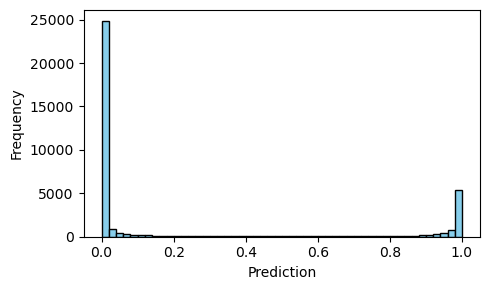

In [24]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))
plt.hist(prediction, bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Prediction')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [25]:
plt.style.use("ggplot")
plt.figure(figsize=(4, 3), dpi=300)

plt.plot(history.history['reconstruction_loss'], label='Reconstruction (MAE)', color='tab:blue')
plt.plot(history.history['classification_loss'], label='Classification (BCE)', color='tab:orange')

plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend()
plt.subplots_adjust(left=0.2, right=0.98, top=0.98, bottom=0.2)
plt.savefig(f"{path}/classification_loss_plot.png")
plt.close()

plt.style.use("ggplot")
plt.figure(figsize=(4, 3), dpi=300)
plt.plot(history.history['val_reconstruction_loss'], label='Reconstruction (MAE)', color='tab:blue')
plt.plot(history.history['val_classification_loss'], label='Classification (BCE)', color='tab:orange')

plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend()
plt.subplots_adjust(left=0.2, right=0.98, top=0.98, bottom=0.2)
plt.savefig(f"{path}/val_classification_loss_plot.png")
plt.close()

plot_classification(history, 1, f"{path}/classification_accuracy_plot.png")
table_save_classification(history, 1, f"{path}/classification_accuracy_table.txt")
